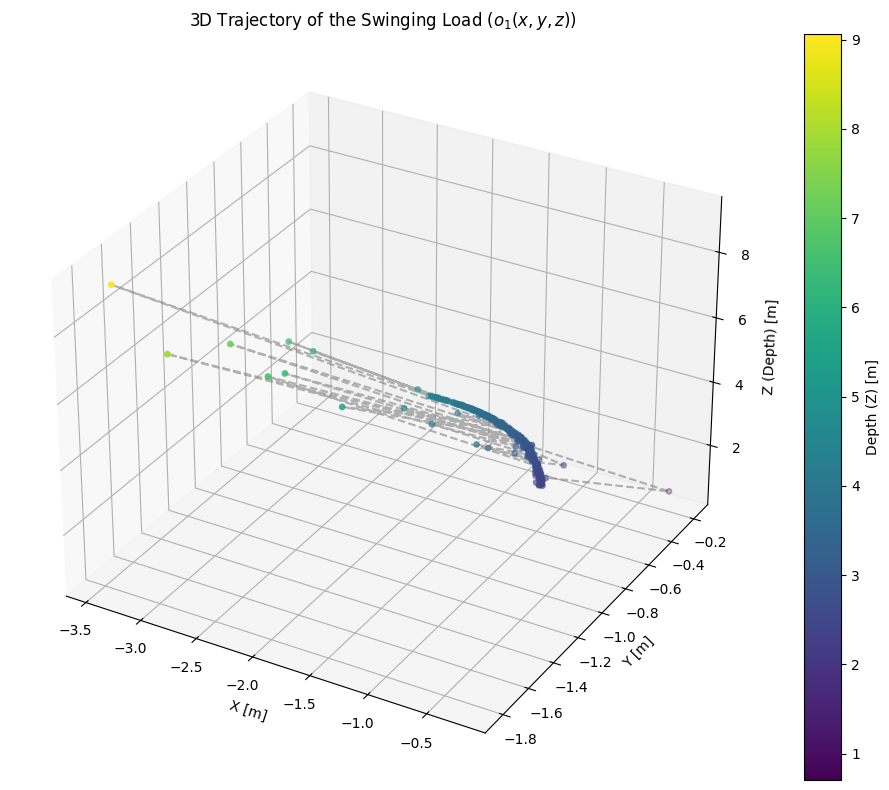

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

base_dir = Path.cwd()
model_path = base_dir / "best.pt"
image_path = base_dir / "data" / "session_20260918_152400_train" / "rgb_frames"
depth_raw_path = base_dir / "data" / "session_20260918_152400_train" / "depth_raw"
json_file = (base_dir / "data" / "session_20260918_152400_train" / "depth_scale_json" / "depth_scale.json")

#Intrinsic camera matrix (M_int) obtained in the lab
fx, fy = 1395.68093, 1395.69633
cx, cy = 917.936973, 513.602178
M_int = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=float)

model = YOLO(str(model_path))

with open(json_file, "r") as f:
  scale_factor = json.load(f)["depth_scale"]

coord_3d = []
rgb_images = sorted(list(image_path.glob("*.png")))
for img in rgb_images:
  results = model(img, verbose=False)[0]
  boxes = results.boxes.xyxy.cpu().numpy()

  if len(boxes) > 0:
    x1, y1, x2, y2 = boxes[0]
    u, v = int((x1 + x2) / 2), int((y1 + y2) / 2)  #Coordinates of the center

    stem = img.stem
    depth_file = depth_raw_path / f"{stem.replace('rgb_', 'depth_')}_raw.npy" #Instead of counting which frame it is, cause it has the same name, we just replace the prefix

    if depth_file.exists():
      depth_data = np.load(depth_file)

      #Small window to avoid null depth values (Yeah, Gemini idea cause if not it looks horrible :/)
      window_size = 3
      v_min = max(0, v - window_size)
      v_max = min(depth_data.shape[0], v + window_size + 1)
      u_min = max(0, u - window_size)
      u_max = min(depth_data.shape[1], u + window_size + 1)

      depth_patch = depth_data[v_min:v_max, u_min:u_max]
      valid_depths = depth_patch[depth_patch > 0]

      if valid_depths.size > 0:
        Z = np.median(valid_depths) * scale_factor

        #Deprojection to 3D coordinates (X, Y, Z) using M_int
        X = (u - cx) * Z / fx
        Y = (v - cy) * Z / fy
        coord_3d.append([X, Y, Z])

coord_3d = np.array(coord_3d)



fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    coord_3d[:, 0],
    coord_3d[:, 1],
    coord_3d[:, 2],
    c=coord_3d[:, 2],
    cmap="viridis",
    s=15,
)

ax.plot(
    coord_3d[:, 0],
    coord_3d[:, 1],
    coord_3d[:, 2],
    color="gray",
    alpha=0.6,
    linestyle="--",
)

ax.set_title("3D Trajectory of the Swinging Load ($o_1(x, y, z)$)")
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z (Depth) [m]")
fig.colorbar(scatter, label="Depth (Z) [m]")

plt.tight_layout()
plt.show()

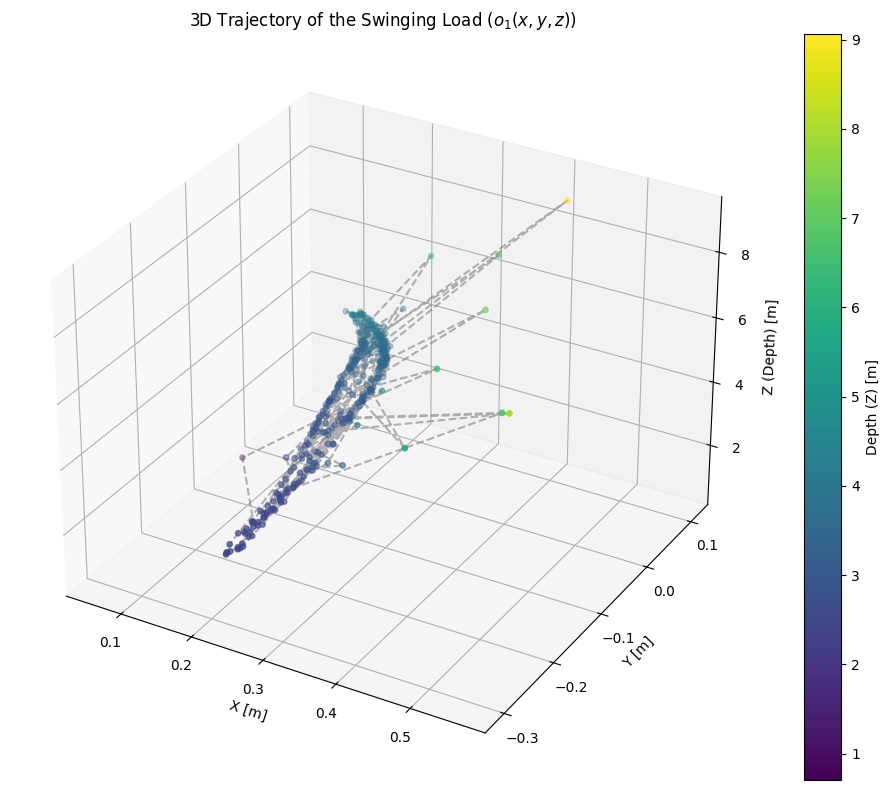

In [ ]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

base_dir = Path.cwd()
model_path = base_dir / "best.pt"
image_path = base_dir / "data" / "session_20260918_152400_train" / "rgb_frames"
depth_raw_path = base_dir / "data" / "session_20260918_152400_train" / "depth_raw"
json_file = (base_dir / "data" / "session_20260918_152400_train" / "depth_scale_json" / "depth_scale.json")

#Intrinsic camera matrix (M_int) obtained in the lab
fx, fy = 1342, 1342
cx, cy = 325, 235
M_int = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=float)

model = YOLO(str(model_path))

with open(json_file, "r") as f:
  scale_factor = json.load(f)["depth_scale"]

coord_3d = []
rgb_images = sorted(list(image_path.glob("*.png")))
for img in rgb_images:
  results = model(img, verbose=False)[0]
  boxes = results.boxes.xyxy.cpu().numpy()

  if len(boxes) > 0:
    x1, y1, x2, y2 = boxes[0]
    u, v = int((x1 + x2) / 2), int((y1 + y2) / 2)  #Coordinates of the center

    stem = img.stem
    depth_file = depth_raw_path / f"{stem.replace('rgb_', 'depth_')}_raw.npy" #Instead of counting which frame it is, cause it has the same name, we just replace the prefix

    if depth_file.exists():
      depth_data = np.load(depth_file)

      #Small window to avoid null depth values (Yeah, Gemini idea cause if not it looks horrible :/)
      window_size = 3
      v_min = max(0, v - window_size)
      v_max = min(depth_data.shape[0], v + window_size + 1)
      u_min = max(0, u - window_size)
      u_max = min(depth_data.shape[1], u + window_size + 1)

      depth_patch = depth_data[v_min:v_max, u_min:u_max]
      valid_depths = depth_patch[depth_patch > 0]

      if valid_depths.size > 0:
        Z = np.median(valid_depths) * scale_factor

        #Deprojection to 3D coordinates (X, Y, Z) using M_int
        X = (u - cx) * Z / fx
        Y = (v - cy) * Z / fy
        coord_3d.append([X, Y, Z])

coord_3d = np.array(coord_3d)



fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    coord_3d[:, 0],
    coord_3d[:, 1],
    coord_3d[:, 2],
    c=coord_3d[:, 2],
    cmap="viridis",
    s=15,
)

ax.plot(
    coord_3d[:, 0],
    coord_3d[:, 1],
    coord_3d[:, 2],
    color="gray",
    alpha=0.6,
    linestyle="--",
)

ax.set_title("3D Trajectory of the Swinging Load ($o_1(x, y, z)$)")
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z (Depth) [m]")
fig.colorbar(scatter, label="Depth (Z) [m]")

plt.tight_layout()
plt.show()

#### **QUESTION 3**: Which intrinsic matrix - 𝑀𝑖𝑛𝑡 𝑜𝑟 𝑀𝑑 is accurate? Give reasons for your answers 

Looking from a **theorical way**, the depth_raw file is provided by the depth sensor of the camera, which is why its own optical parameters must be used. 

But if we see it from a **practical way**, we must know that The Intel RealSense LiDAR Camera L515 features a 1.88 mm focal length for its RGB camera lens. Given the Instrinsic Matrix:

$$\text{Focal (mm)} = f_x \times s_x$$

Where:
- fx (element at position [0, 0]): The horizontal focal length (measured in pixels).
- s_x: The physical size of the camera sensor pixel in mm/pixel (according to the documentation is 1.4 µm) 

The best result is the one closest to 1.88 mm. 
So we do the math and with Mint = 1953 µm = **1.953 mm** and with Md = 1878.8 µm = **1.8788 mm**

So the answer to which is more accurate is Md.


